**About Project:**
Tetouan's power grid is divided into three electrical distribution zones, each zone serves a different set of residential and commercial customers with distinct consumption behavior. Accurately forecasting zone-level power demand is essential for efficient resource allocation, demand planning, and capacity investment decisions. 

This project analyzes 10-minute interval power consumption and weather data across the three zones to identify consumption patterns.

A **Multi-output Random Forest Regressor model** is used to forecast demand from weather and time features, and a **per-zone SARIMA model** is used to evaluate time-series forecasting performance.

**About Dataset:**
This dataset is from the UCI Machine Learning Repository (https://archive.ics.uci.edu/dataset/849/power+consumption+of+tetouan+city). 
The dataset captures power consumption readings recorded every 10-minutes throughout 2017 across three distribution zones in Tetouan, a city in northern Morocco. 
It contains 52,416 records with six input features: DateTime, Temperature, Humidity, Wind Speed, General Diffuse Flows, and Diffuse Flows.

Dataset: Tetuan_City_power_consumption.csv

Three target variables: Zone 1, Zone 2, and Zone 3 Power Consumption.


In [1]:
# Importing all the libraries
import pandas as pd
import random as rnd
import numpy as np
import seaborn as sns
import logging
import matplotlib.pyplot as plt

from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.multioutput import MultiOutputRegressor
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import (
    accuracy_score,
    mean_absolute_error,
    mean_squared_error,
    cohen_kappa_score,
    classification_report,
    confusion_matrix,
    r2_score
)

from scipy.stats import skew
from scipy.stats import ttest_ind

from sklearn import set_config

sns.set_theme(style="whitegrid")

set_config(display='text')
pd.set_option('display.max_columns',50) # setting up the dataframe display columns
pd.set_option('display.max_colwidth', 200) # setting up column width 100
pd.set_option('display.expand_frame_repr', False)


### Loading data file

I downloaded "Tetuan City power consumption.csv" file from UCI Machine Learning Repository

In [2]:
file_tetuan_city= 'Tetuan_City_power_consumption.csv' # file is saved in current directory.

# Catch any exception reading file
try:
    df_power = pd.read_csv(f"{file_tetuan_city}", sep = ",")
except FileNotFoundError as e: # if file is not not found. 
    logging.error(f"{file_tetuan_city} is not found, please check the file path or name.\n{e}")

In [3]:
df_power.head()

,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


## Exploratory Data Analysis (EDA)

Analyzing, data cleaning, and visualizing datasets and identifying underlying patterns of the data.

In [4]:
df_power.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   DateTime                   52416 non-null  object 
 1   Temperature                52416 non-null  float64
 2   Humidity                   52416 non-null  float64
 3   Wind Speed                 52416 non-null  float64
 4   general diffuse flows      52416 non-null  float64
 5   diffuse flows              52416 non-null  float64
 6   Zone 1 Power Consumption   52416 non-null  float64
 7   Zone 2  Power Consumption  52416 non-null  float64
 8   Zone 3  Power Consumption  52416 non-null  float64
dtypes: float64(8), object(1)
memory usage: 3.6+ MB


I do find any NaN values.

In [5]:
# Checking any duplicate rows
df_power.duplicated().sum()

np.int64(0)

No duplicate values in dataset.

In [6]:
# Remove the double space in column names
df_power.columns = df_power.columns.str.replace(r'\s+', ' ', regex=True).str.strip()

In [7]:
# Checking any duplicate DateTime entries specifically.
# It is separate from full-row duplicates values.

df_power['DateTime'].duplicated().sum()

np.int64(0)

No duplicate DateTime values in dataset.

#### Datetime conversion and feature extraction

In [8]:
# Converting DateTime to datetime dtype
df_power['DateTime'] = pd.to_datetime(df_power['DateTime'])

df_pw = df_power.copy()

# Extracting temporal features for EDA and modeling
df_pw['hour']        = df_pw['DateTime'].dt.hour
df_pw['day_of_week']  = df_pw['DateTime'].dt.dayofweek   # 0=Monday to 6=Sunday
df_pw['day_name']    = df_pw['DateTime'].dt.day_name()
df_pw['month']       = df_pw['DateTime'].dt.month
df_pw['month_name']  = df_pw['DateTime'].dt.month_name()
df_pw['is_weekend']  = df_pw['day_of_week'].isin([5, 6]).astype(int)  # Sat or Sun, Weekend = 1

df_pw.head()

# Monday=0 to Sunday=6, It is pandas default standard. 
# It is an internal feature only used for grouping/plotting, actual numbering does not affect any results either way.

,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption,hour,day_of_week,day_name,month,month_name,is_weekend
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386,0,6,Sunday,1,January,1
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434,0,6,Sunday,1,January,1
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373,0,6,Sunday,1,January,1
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711,0,6,Sunday,1,January,1
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964,0,6,Sunday,1,January,1


Time trends — weather and consumption across the year:



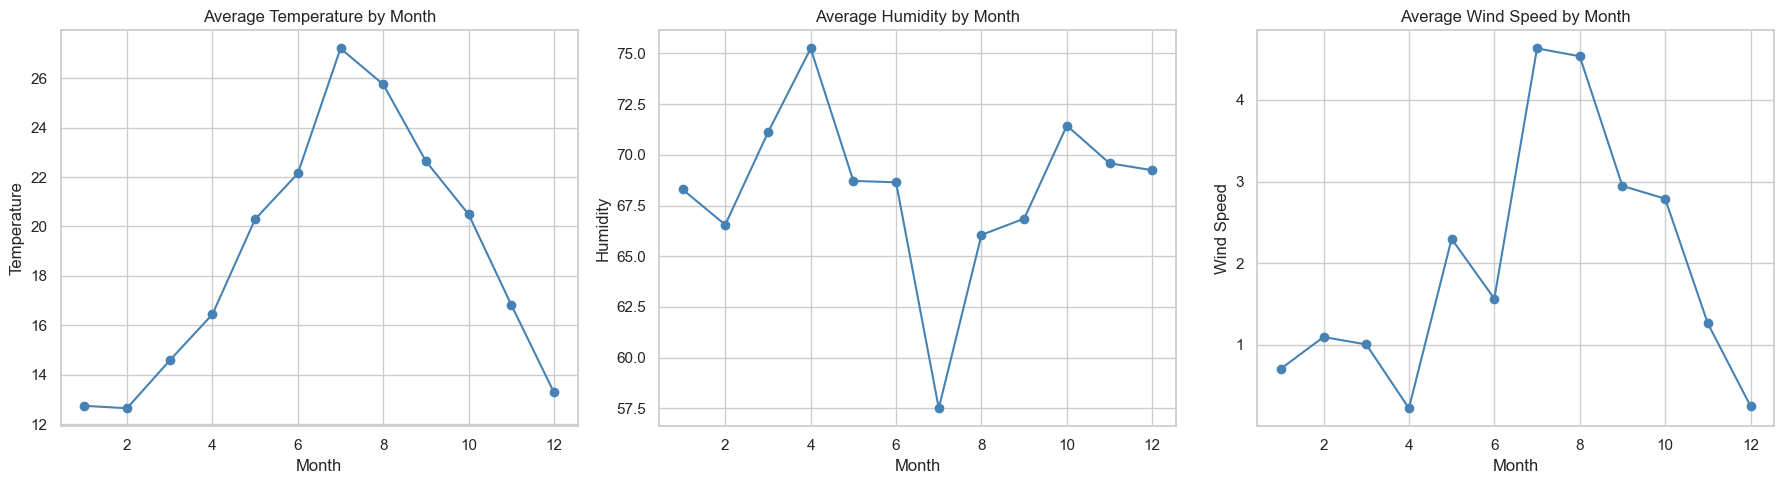

In [9]:
# Time trends — weather and consumption across the year

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
weather_cols = ['Temperature', 'Humidity', 'Wind Speed']

for ax, col in zip(axes, weather_cols):
    monthly_avg = df_pw.groupby('month')[col].mean()
    ax.plot(monthly_avg.index, monthly_avg.values, marker='o', color='steelblue')
    ax.set_title(f'Average {col} by Month')
    ax.set_xlabel('Month')
    ax.set_ylabel(col)

print('Time trends — weather and consumption across the year:\n')
plt.tight_layout()
plt.show()

Temperature is low in January (13°C) and peaks in July (27°C), following a seasonal cycle.

Humidity dips in July (57.5%) as temperatures peak (hot), with dry summer conditions. 

Wind Speed spikes in June–August (4.5–4.7).

Monthly consumption per zone:



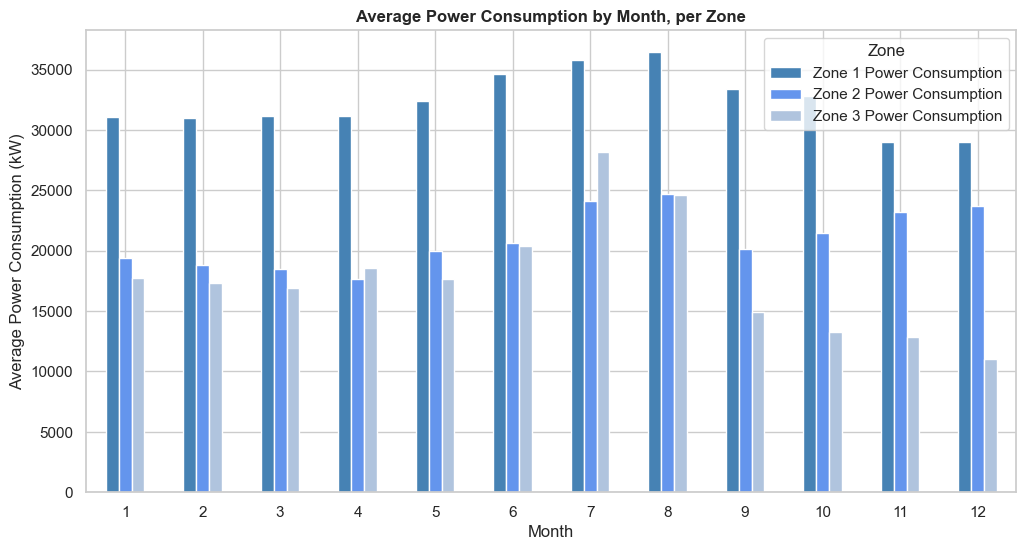

In [10]:
# monthly consumption per zone
zone_cols = ['Zone 1 Power Consumption', 'Zone 2 Power Consumption', 'Zone 3 Power Consumption']

monthly_zone_avg = df_pw.groupby('month')[zone_cols].mean()

plt.figure(figsize=(12, 6))
monthly_zone_avg.plot(kind='bar', ax=plt.gca(), color=['steelblue', 'cornflowerblue', 'lightsteelblue'])
plt.title('Average Power Consumption by Month, per Zone', fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Average Power Consumption (kW)')
plt.legend(title='Zone')
plt.xticks(rotation=0)

print('Monthly consumption per zone:\n')
plt.show()



Zone 1 peaks in August.
    
Zone 2 and Zone 3 both peak in July.

Average Power Consumption by Day of Week, per Zone:



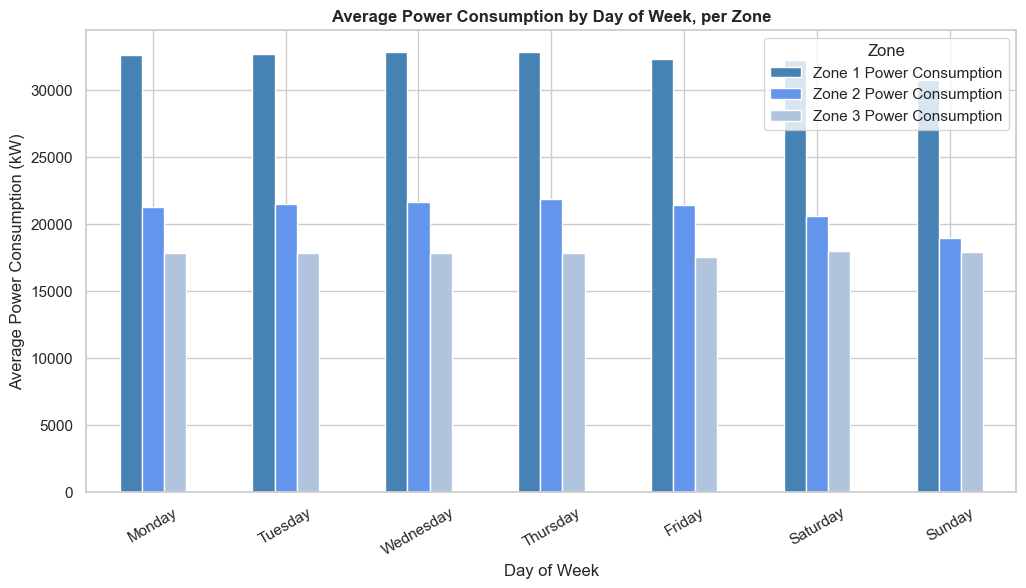

In [11]:
# Average Power Consumption by Day of Week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_avg = df_pw.groupby('day_name')[zone_cols].mean().reindex(day_order)

dow_avg.plot(kind='bar', figsize=(12, 6), color=['steelblue', 'cornflowerblue', 'lightsteelblue'])
plt.title('Average Power Consumption by Day of Week, per Zone', fontweight='bold')
plt.xlabel('Day of Week')
plt.ylabel('Average Power Consumption (kW)')
plt.xticks(rotation=30)
plt.legend(title='Zone')

print('Average Power Consumption by Day of Week, per Zone:\n')
plt.show()

Consumption is almost flat across the week for all three zone.

Daily Average Power Consumption Over Time (2017:



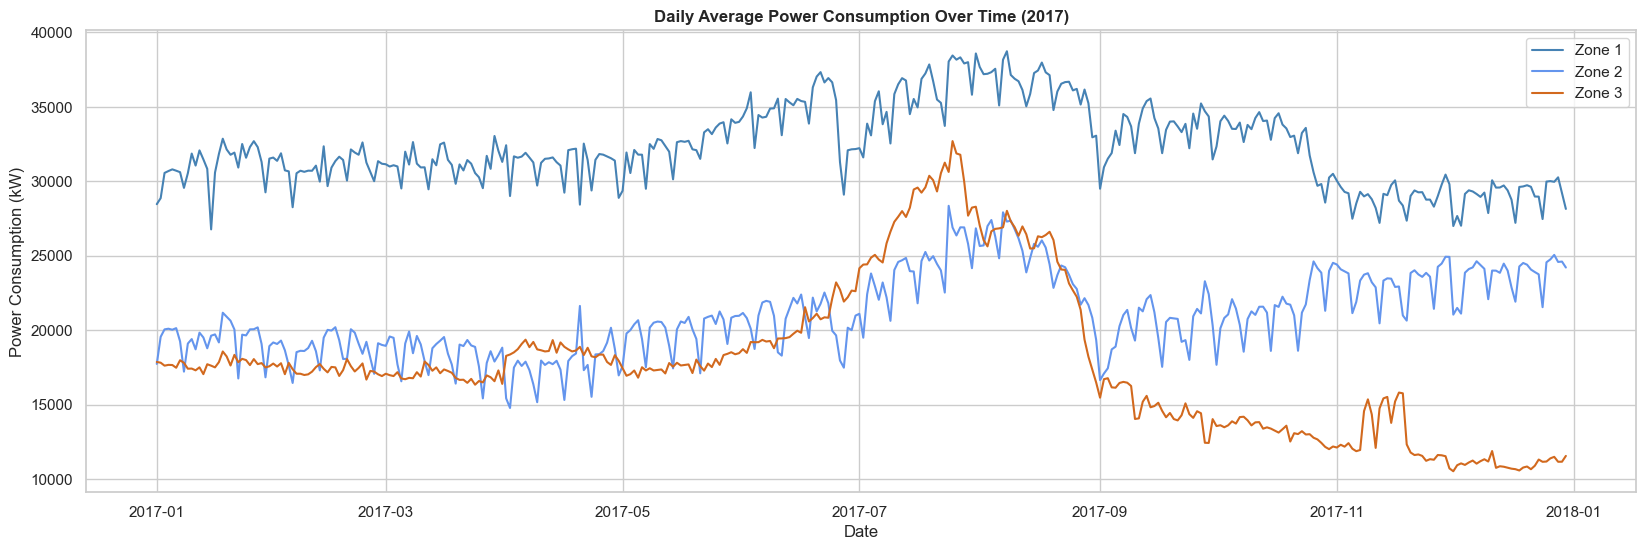

In [12]:
# Daily trend over the year

daily_avg = df_pw.set_index('DateTime')[zone_cols].resample('D').mean()

plt.figure(figsize=(20, 6))
plt.plot(daily_avg.index, daily_avg['Zone 1 Power Consumption'], label='Zone 1', color='steelblue')
plt.plot(daily_avg.index, daily_avg['Zone 2 Power Consumption'], label='Zone 2', color='cornflowerblue')
plt.plot(daily_avg.index, daily_avg['Zone 3 Power Consumption'], label='Zone 3', color='chocolate')
plt.title('Daily Average Power Consumption Over Time (2017)', fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Power Consumption (kW)')
plt.legend()

print('Daily Average Power Consumption Over Time (2017:\n')
plt.show()

Zone 1 stays mostly stable year-round (matches its low CV).

Zone 3 shows a sharp summer spike (June–August), then drops to a much lower level. It is the most volatile and independent zone. 

Zone 3's swing size also grows with its level (large summer amplitude, small winter amplitude). 
This suggests a log transform may be worth applying before fitting SARIMA on Zone 3.

**Note**: SARIMA has no separate features. The series itself, Zone 3's consumption, is both input and output. It forecasts each value from the series' own past values and past errors, so the model fits directly to the target's scale and variance behavior.

In [13]:
zone_cols = ['Zone 1 Power Consumption', 'Zone 2 Power Consumption', 'Zone 3 Power Consumption']

numeric_cols = ['Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows',
                 'diffuse flows'] + zone_cols

# Descriptive statistics for numeric columns
print("Descriptive statistics:")
df_pw[numeric_cols].describe()

Descriptive statistics:


,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
count,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000
mean,18.810024,68.259518,1.959489,182.696614,75.028022,32344.970564,21042.509082,17835.406218
std,5.815476,15.551177,2.348862,264.400960,124.210949,7130.562564,5201.465892,6622.165099
min,3.247000,11.340000,0.050000,0.004000,0.011000,13895.696200,8560.081466,5935.174070
25%,14.410000,58.310000,0.078000,0.062000,0.122000,26310.668692,16980.766032,13129.326630
50%,18.780000,69.860000,0.086000,5.035500,4.456000,32265.920340,20823.168405,16415.117470
75%,22.890000,81.400000,4.915000,319.600000,101.000000,37309.018185,24713.717520,21624.100420
max,40.010000,94.800000,6.483000,1163.000000,936.000000,52204.395120,37408.860760,47598.326360


There is **no negative** values.

Zone 1 is the largest zone, it has mean = 32345 kW, roughly 54% more than Zone 2 = 21043 and 81% than Zone 3 = 17835 kw.

**Zone 3 is right-skewed** (mean 17,835 > median 16,415, a ~1,420 gap), other two zones are close to symmetric (Zone 1: mean 32,345 vs median 32,266; Zone 2: mean 21,043 vs median 20,823). Zone 3 high-end outliers.

Wind Speed: 25th and 50th percentile are both ~0.08, but the 75th percentile is 4.9, it looks a a **bimodal distribution**.

general diffuse flows and diffuse flows: both have medians near zero (5.0 and 4.5) but means is higher (183 and 75). 
It looks like zero at night, high at midday, **heavily right-skewed**, is expected, **not a data quality issue**.


In [14]:
# Standard deviation per zone
zone_std = df_pw[zone_cols].std().sort_values(ascending=False)
print("Standard deviation per zone (higher = more variable):")
print(zone_std)

Standard deviation per zone (higher = more variable):
Zone 1 Power Consumption    7130.562564
Zone 3 Power Consumption    6622.165099
Zone 2 Power Consumption    5201.465892
dtype: float64


In absolute terms, **Zone 1 has the largest swings in demand** (std ≈ 7,131 kW). But relative to its own typical load, **Zone 3 is the most volatile zone** (CV ≈ 0.37).

**Zone 3's demand is hardest to predict.**

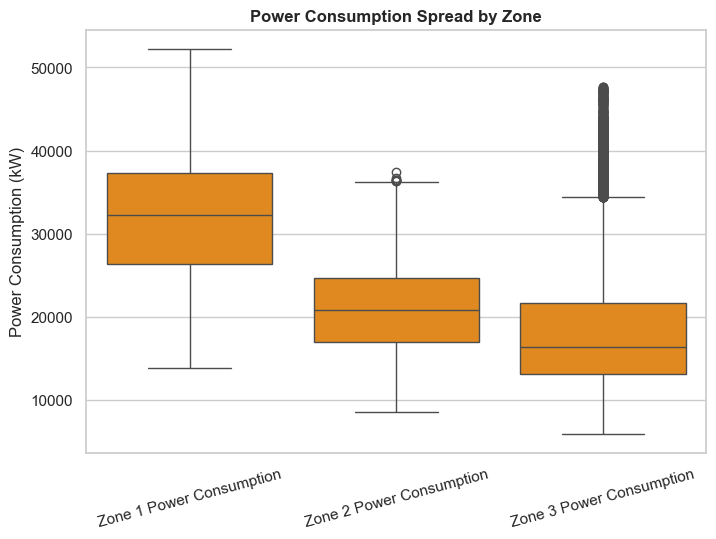

In [15]:
# Boxplot per zone
plt.figure(figsize=(8, 5.5))
sns.boxplot(data=df_pw[zone_cols], color='darkorange')
plt.title('Power Consumption Spread by Zone', fontweight='bold')
plt.ylabel('Power Consumption (kW)')
plt.xticks(rotation=15)
plt.show()

Zone 1: no outliers at all.
    
Zone 2: a couple of mild outliers just above ~36,000–37,000 kW.

Zone 3: a dense cluster of outliers stacked above ~34,300 kW.
    

#### IQR statistics: Outliers analysis


Q1 = 0.25 and Q3 = 0.75
IQR Outlier Summary:
                            Q1       Q3      IQR  Lower Bound  Upper Bound  Outlier Count  Outlier %
Temperature            14.410   22.890    8.480       1.6900      35.6100          142.0       0.27
Humidity               58.310   81.400   23.090      23.6750     116.0350          291.0       0.56
Wind Speed              0.078    4.915    4.837      -7.1775      12.1705            0.0       0.00
general diffuse flows   0.062  319.600  319.538    -479.2450     798.9070         2315.0       4.42
diffuse flows           0.122  101.000  100.878    -151.1950     252.3170         4571.0       8.72


***** Boxplots *****


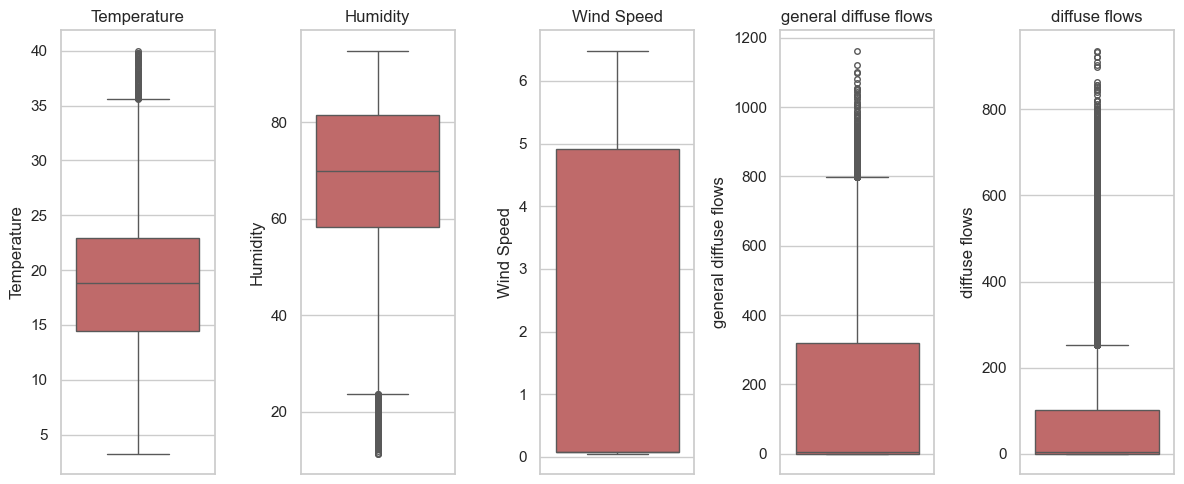

In [16]:
# Candidate numeric columns for df_pw (weather features only, excludes targets)
numeric_cols = ['Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows', 'diffuse flows']

lower_limit = 0.25
upper_limit = 0.75

def detect_outliers_iqr(data, column, lower_limit, upper_limit):
    Q1 = data[column].quantile(lower_limit)
    Q3 = data[column].quantile(upper_limit)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    return Q1, Q3, IQR, lower_bound, upper_bound, outliers

# store results
iqr_results = {}
for col in numeric_cols:
    Q1, Q3, IQR, lower, upper, outliers = detect_outliers_iqr(df_pw, col, lower_limit, upper_limit)
    iqr_results[col] = {'Q1': Q1, 'Q3': Q3, 'IQR': IQR,
                         'Lower Bound': lower, 'Upper Bound': upper,
                         'Outlier Count': len(outliers),
                         'Outlier %': round(len(outliers) / len(df_pw) * 100, 2)}

# dataframe with IQR summary
iqr_df = pd.DataFrame(iqr_results).T
print(f"\nQ1 = {lower_limit} and Q3 = {upper_limit}\nIQR Outlier Summary:\n", iqr_df)

print("\n\n***** Boxplots *****")
plt.figure(figsize=(12, 5))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(1, 5, i)
    sns.boxplot(y=df_pw[col], color='indianred', fliersize=4)
    plt.title(f'{col}')
plt.tight_layout()
plt.show()

Temperature/Humidity: Not a huge number of outliers. No action is needed.
    
Wind Speed: zero outliers.

general diffuse flows and diffuse flows: They are the expected shape of solar radiation data. Both are near zero for roughly half the day (nighttime); we have checked this in descriptive statistics. It has a spike during daylight hours. IQR treats the daytime peak values as outliers because they are compressed relative to the near-zero nighttime values. **It is not data anomalies**. 

So, No outliers are removed here.

#### Histograms - Weather variables

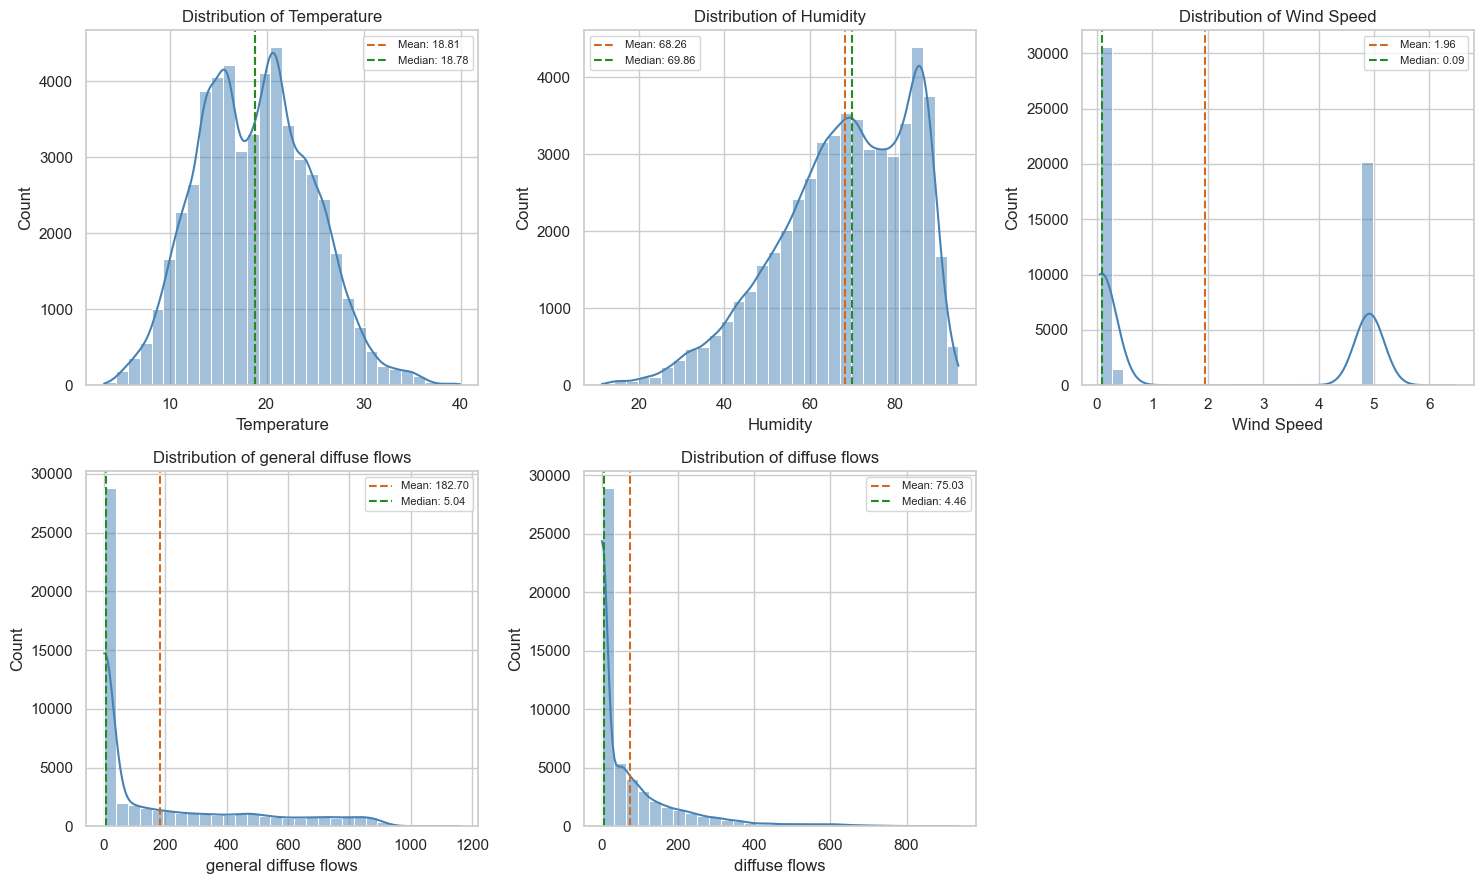

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    sns.histplot(df_pw[col], bins=30, kde=True, color='steelblue', ax=ax)

    mean_val = df_pw[col].mean()
    median_val = df_pw[col].median()

    ax.axvline(mean_val, color='chocolate', linestyle='--', linewidth=1.5, label=f'Mean: {mean_val:.2f}')
    ax.axvline(median_val, color='forestgreen', linestyle='--', linewidth=1.5, label=f'Median: {median_val:.2f}')

    ax.set_title(f'Distribution of {col}')
    ax.legend(fontsize=8)

# Hiding any unused subplot (5 features into a 6-slot grid leaves one empty)
for ax in axes[len(numeric_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

**Temperature is slightly bimodal, not skewed.** Two peaks around 15°C and 21°C are not a skew problem. They are very likely the day/night or seasonal split. 
Humidity is mildly left-skewed. A long, thin tail toward low values, mostly concentrated at 60–90, with a small spike near the max (85–90). It matches the mean (68.26) < median (69.86) observed in the descriptive statistics.

**Wind Speed is a bimodal**. It looks like there are two distinct wind, a large calm cluster near 0 (30K readings) and a separate windy cluster around 5 (20K readings), with almost nothing in between. It is explicitly two operating conditions, not a continuous spread.

**General diffuse flows are extremely right-skewed.** It has a big spike near zero (maybe nighttime), then a long, thin tail out to 1000+ / 900+ (maybe midday peaks). 

**Random Forest splits on threshold rules (is Wind Speed > 2.3?), not on distances or linear combinations like other projects, K-Means, or linear regression.** A monotonic transform like log or sqrt does not change which side of a threshold a value falls on. So skew has almost zero effect on what RF can learn from a feature. This is different from other project work, the K-Means case, where the skew directly distorted Euclidean distances between points and needed a feature transformation to fix.

**So, we are keeping all 5 features untransformed for the RF model.**

**SARIMA models** a series against its own past values, not feature-to-target relationships. SARIMA does care about the stability of variance over time. Based on the histogram shapes and expected consumption patterns, no separate skewness test or transformation is planned for SARIMA at this phase. 

We will revisit only if the time series plot shows swings that scale with the demand level.

In [18]:
print("Skewness per feature:")
print(df_pw[numeric_cols].skew())

Skewness per feature:
Temperature              0.196719
Humidity                -0.625166
Wind Speed               0.462423
general diffuse flows    1.306973
diffuse flows            2.456907
dtype: float64


Here, Skewness values confirm that Temperature and Wind Speed are almost symmetric, Humidity is moderately skewed, and both solar flow columns (general diffuse flows and diffuse flows) are highly right-skewed (general diffuse flows = 1.31, diffuse flows = 2.46), maybe due to the expected day/night solar cycle.

No transformation is applied, since Random Forest splits on thresholds. 

#### Correlation - feature-vs-feature and feature-vs-target

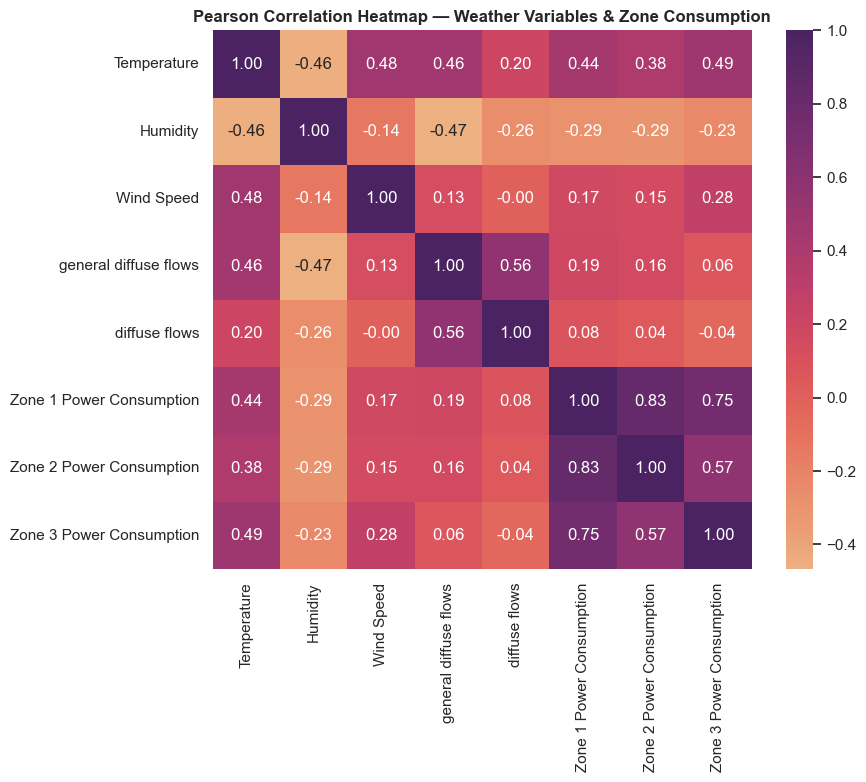

In [19]:
corr_cols = ['Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows',
             'diffuse flows'] + zone_cols

corr_matrix = df_pw[corr_cols].corr(method='pearson')

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="flare", cbar=True, square=True)
plt.title("Pearson Correlation Heatmap — Weather Variables & Zone Consumption", fontweight='bold')
plt.show()

general diffuse flows vs. diffuse flows = 0.56. This is a moderate correlation. I will keep both in input feature list.

Temperature is the strongest weather predictor for all three zones.
    
Humidity is negative here, which means higher humidity and lower consumption.
    
Wind Speed and both solar-flow features have a weak correlation with all three zones. 
    
diffuse flows  is close to zero for every zone. It is probably a weak predictor, but we are still keeping it in the RF feature list, since Pearson only captures linear relationships, and RF can still extract non-linear values from it.

We drop features for high correlation (redundancy), and near-zero correlation means the are opposite and independent.

**high correlation -> candidate to drop one (redundant).** 
    
**Low/zero correlation -> keep both (independent, non-overlapping sgnal).**

### Statistical significance — Independent t-test (Weekday vs. Weekend)

A t-test is a statistical test to checks whether the difference between two group means is real, or just something that could easily happen by chance from random variation in the data.

**Null Hypothesis** H₀ - There is no difference between the groups or between the sample mean and a reference value. It assumes that any observed difference is due to random chance.

**Alternative Hypothesis** H₁ - There is a difference between the groups or between the sample mean and the reference value.

In [20]:
# Statistical significance — Independent t-test (Weekday vs. Weekend)

for zone in zone_cols:
    weekday_vals = df_pw[df_pw['is_weekend'] == 0][zone]
    weekend_vals = df_pw[df_pw['is_weekend'] == 1][zone]

    t_stat, p_value = ttest_ind(weekday_vals, weekend_vals, equal_var=False)

    print(f"\n{zone}")
    print(f"  Weekday mean: {weekday_vals.mean():.2f}   Weekend mean: {weekend_vals.mean():.2f}")
    print(f"  T-statistic: {t_stat:.3f}")
    print(f"  p-value: {p_value:.5f}")
    print(f"  Statistically significant? {'Yes' if p_value < 0.05 else 'No'}")


Zone 1 Power Consumption
  Weekday mean: 32676.34   Weekend mean: 31516.56
  T-statistic: 16.902
  p-value: 0.00000
  Statistically significant? Yes

Zone 2 Power Consumption
  Weekday mean: 21546.45   Weekend mean: 19782.67
  T-statistic: 35.562
  p-value: 0.00000
  Statistically significant? Yes

Zone 3 Power Consumption
  Weekday mean: 17776.37   Weekend mean: 17983.01
  T-statistic: -3.204
  p-value: 0.00136
  Statistically significant? Yes


Null hypothesis H₀: For each zone, there is no real difference in average power consumption between weekdays and weekends, any observed gap is just random chance. 

Alternative hypothesis H₁: There is a genuine difference in average consumption between weekdays and weekends.

Here, p-value (< 0.05) for all zones, **I reject the null hypothesis in every zone. There is a statistically significant difference between weekday and weekend consumption in all three zones.**

Note: Averaging 5 weekday values vs. 2 weekend values does not automatically create a difference; if daily demand were similar across all 7 days, both means would come out nearly equal regardless of the 5:2 split.

## Model01- Random Forest Regressor

**Forecasting Electricity Consumption**

In [21]:
# Add lag and rolling features per zone, 24 hours before the target, it is a day-ahead forecast
# lag144_24hr = 24 hours ago
# roll_mean_6_24hr = 1-hour average window, ending 24 hours before the target

target_cols = ['Zone 1 Power Consumption', 'Zone 2 Power Consumption', 'Zone 3 Power Consumption']
df_pw_lagged24 = df_pw.sort_values('DateTime').reset_index(drop=True).copy()

for zone in target_cols:
    df_pw_lagged24[f'{zone}_lag144_24hr'] = df_pw_lagged24[zone].shift(144)
    df_pw_lagged24[f'{zone}_roll_mean_6_24hr'] = df_pw_lagged24[zone].rolling(6).mean().shift(144)

df_pw_lagged24 = df_pw_lagged24.dropna().reset_index(drop=True)
print(f"Rows before: {len(df_pw)}, \nRows after dropping NaN: {len(df_pw_lagged24)}")

Rows before: 52416, 
Rows after dropping NaN: 52267


In [22]:
# Input and leg features
rf_features_24hr = ['hour', 'day_of_week', 'month',
                     'Temperature', 'Humidity', 'Wind Speed',
                     'general diffuse flows', 'diffuse flows']

lag_features_24hr = []
for zone in target_cols:
    lag_features_24hr += [f'{zone}_lag144_24hr', f'{zone}_roll_mean_6_24hr']
rf_features_24hr = rf_features_24hr + lag_features_24hr

X = df_pw_lagged24[rf_features_24hr].copy()
y = df_pw_lagged24[target_cols].copy()

print("Feature matrix shape:", X.shape)
print("Features:", rf_features_24hr)

Feature matrix shape: (52267, 14)
Features: ['hour', 'day_of_week', 'month', 'Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows', 'diffuse flows', 'Zone 1 Power Consumption_lag144_24hr', 'Zone 1 Power Consumption_roll_mean_6_24hr', 'Zone 2 Power Consumption_lag144_24hr', 'Zone 2 Power Consumption_roll_mean_6_24hr', 'Zone 3 Power Consumption_lag144_24hr', 'Zone 3 Power Consumption_roll_mean_6_24hr']


In [23]:
# Splitting dataset into train and test
split_index = int(len(df_pw_lagged24) * 0.8)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]
print(f"Train size: {len(X_train)} ({X_train.shape[0]/len(df_pw_lagged24):.1%})")
print(f"Test size: {len(X_test)} ({X_test.shape[0]/len(df_pw_lagged24):.1%})")

Train size: 41813 (80.0%)
Test size: 10454 (20.0%)


In [24]:
# Random Forest Regressor
rf_pipe = Pipeline([
    ('model', MultiOutputRegressor(RandomForestRegressor(random_state=42, n_jobs=-1)))
])
rf_param_grid = {
    'model__estimator__n_estimators': [50, 100],
    'model__estimator__max_depth': [10, 15],
    'model__estimator__min_samples_split': [2, 5]
}
rf_grid = GridSearchCV(rf_pipe, rf_param_grid, cv=3, scoring='neg_root_mean_squared_error', n_jobs=-1)

rf_grid.fit(X_train, y_train)
print(f"Best Hyperparameters: {rf_grid.best_params_}")
print(f"Best CV RMSE: {-rf_grid.best_score_:.2f}")

Best Hyperparameters: {'model__estimator__max_depth': 10, 'model__estimator__min_samples_split': 2, 'model__estimator__n_estimators': 100}
Best CV RMSE: 1528.63


Best model: max_depth=15, min_samples_split=2, n_estimators=50, with a cross-validated RMSE of 910.64 across the three zones.

In [35]:
# predicting power consumption
y_pred = rf_grid.predict(X_test)

results = {}
for i, zone in enumerate(target_cols):
    rmse = np.sqrt(mean_squared_error(y_test.iloc[:, i], y_pred[:, i]))
    mae = mean_absolute_error(y_test.iloc[:, i], y_pred[:, i])
    r2 = r2_score(y_test.iloc[:, i], y_pred[:, i])
    results[zone] = {'RMSE': rmse, 'MAE': mae, 'R2': r2}

results_df = pd.DataFrame(results).T.round(2)
print("Multi-Output Random Forest Regressor:\n")
print(results_df)

Multi-Output Random Forest Regressor:

                             RMSE      MAE    R2
Zone 1 Power Consumption  2951.72  2545.26  0.77
Zone 2 Power Consumption  2505.45  1945.99  0.79
Zone 3 Power Consumption  1785.54  1401.79  0.71


The Multi-Output Random Forest Regressor is predicting power consumption across Zone 1, Zone 2, and Zone 3 of the Tetouan grid. 

R² ranges from 0.71 to 0.79 across the three zones, explaining the large majority of variance in each zone's consumption. 

MAE ranges from 1401 to 2545 kW; on average, our predictions are off by 1,964kW.

Actual vs. Predicted scatter, per zone (24-hour day-ahead forecast):



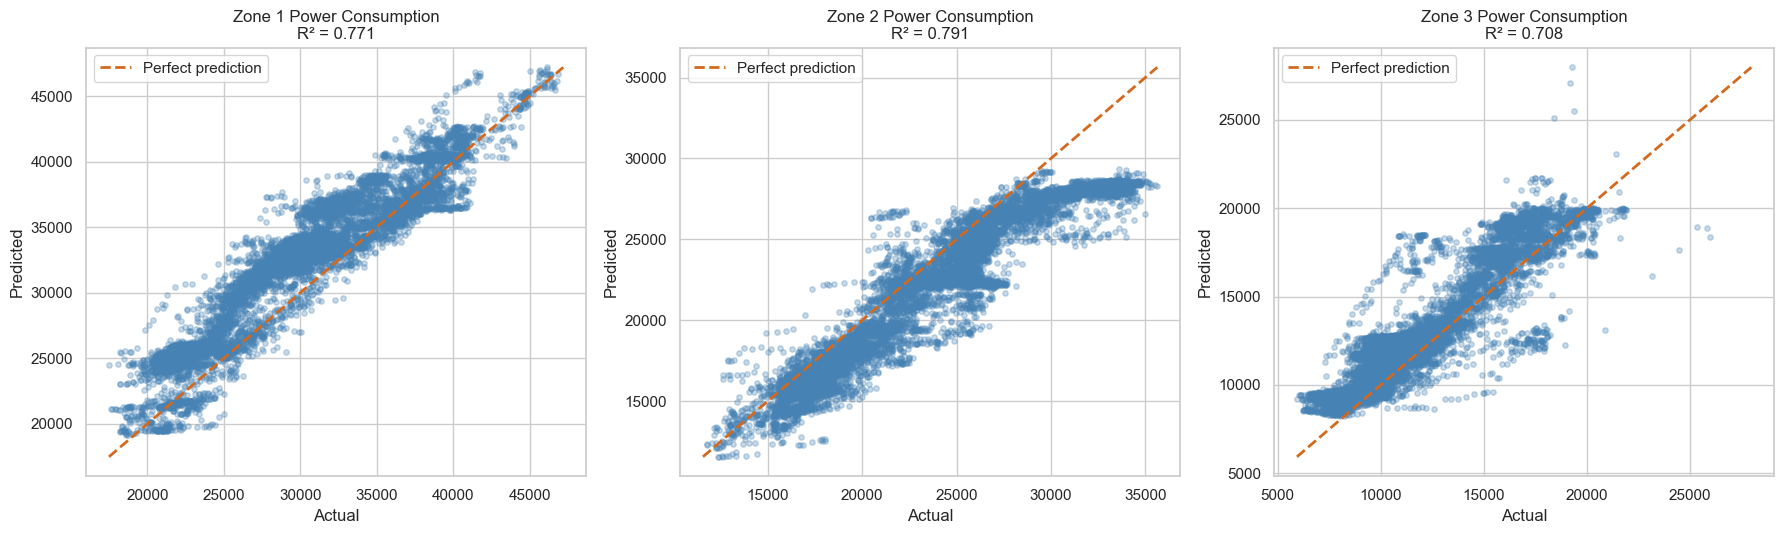

In [26]:
# Actual vs. Predicted scatter, per zone
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, zone, i in zip(axes, target_cols, range(3)):
    ax.scatter(y_test.iloc[:, i], y_pred[:, i], alpha=0.3, color='steelblue', s=15)
    min_val = min(y_test.iloc[:, i].min(), y_pred[:, i].min())
    max_val = max(y_test.iloc[:, i].max(), y_pred[:, i].max())
    ax.plot([min_val, max_val], [min_val, max_val],
            color='chocolate', linestyle='--', linewidth=2, label='Perfect prediction')
    ax.set_xlabel('Actual')
    ax.set_ylabel('Predicted')
    ax.set_title(f'{zone}\nR² = {r2_score(y_test.iloc[:, i], y_pred[:, i]):.3f}')
    ax.legend()

print('Actual vs. Predicted scatter, per zone (24-hour day-ahead forecast):\n')
plt.tight_layout()
plt.show()

In [31]:
# Feature importance (24-hour day-ahead model)
best_model = rf_grid.best_estimator_.named_steps['model']

importance_data = {}
for i, zone in enumerate(target_cols):
    importance_data[zone] = best_model.estimators_[i].feature_importances_

importance_df = pd.DataFrame(importance_data, index=rf_features_24hr)
print('Feature importance in Random Forest Regressor (24-hour day-ahead forecast):\n')
print(importance_df.round(4))

Feature importance in Random Forest Regressor (24-hour day-ahead forecast):

                                           Zone 1 Power Consumption  Zone 2 Power Consumption  Zone 3 Power Consumption
hour                                                         0.0162                    0.0075                    0.0008
day_of_week                                                  0.0139                    0.0335                    0.0017
month                                                        0.0021                    0.0029                    0.0011
Temperature                                                  0.0029                    0.0061                    0.0008
Humidity                                                     0.0019                    0.0024                    0.0007
Wind Speed                                                   0.0010                    0.0020                    0.0006
general diffuse flows                                        0.0020                

**Each zone's own recent history is most important feature in predicitng the power consumption.**

Zone 1 relies on its lag144_24hr (0.94)

Zone 2 depends on its lag144_24hr (0.74)

Zone 3 depends on its lag144_24hr (0.99)

## Model02 - SARIMA (Seasonal ARIMA) - per-zone time series forecasting

SARIMA has no feature columns, and it only checks one single column, the zone's own consumption values over time.

In [32]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [33]:
def run_sarima_zone(zone_name, order=(1,1,1), seasonal_order=(1,1,1,24), horizon=48):
    '''
    Function resamples a zone's 10-minute data to hourly.
    Splits it 80/20 chronologically, fits a SARIMA model on the training portion.
    Forecasts the first horizon hours (48 by default) into the test period, 
    prints MAE/RMSE/R² comparing the forecast to actual values.
    '''
    ts = df_pw.set_index('DateTime')[zone_name].resample('h').mean()
    train_size = int(len(ts) * 0.8)
    train, test = ts.iloc[:train_size], ts.iloc[train_size:]

    model = SARIMAX(train, order=order, seasonal_order=seasonal_order,
                     enforce_stationarity=False, enforce_invertibility=False)
    result = model.fit(disp=False)

    forecast = result.get_forecast(steps=horizon)
    forecast_mean = forecast.predicted_mean
    actual = test.iloc[:horizon]

    mae = mean_absolute_error(actual, forecast_mean)
    rmse = np.sqrt(mean_squared_error(actual, forecast_mean))
    r2 = r2_score(actual, forecast_mean)

    print(f"{zone_name} (SARIMA, {horizon}hr): MAE={mae:.2f}, RMSE={rmse:.2f}, R2={r2:.4f}")
    return result, forecast_mean, actual

In [34]:
# Running for all three zones
sarima_results = {}
sarima_results['Zone 1'] = run_sarima_zone('Zone 1 Power Consumption')
sarima_results['Zone 2'] = run_sarima_zone('Zone 2 Power Consumption')
sarima_results['Zone 3'] = run_sarima_zone('Zone 3 Power Consumption')

Zone 1 Power Consumption (SARIMA, 48hr): MAE=730.78, RMSE=895.30, R2=0.9796
Zone 2 Power Consumption (SARIMA, 48hr): MAE=474.04, RMSE=646.29, R2=0.9730
Zone 3 Power Consumption (SARIMA, 48hr): MAE=817.27, RMSE=955.65, R2=0.8927


**Over a 48-hour forecast horizon, SARIMA provides a good accuracy for all three zones (R² 0.89-0.98).**
    
Zone 1 and Zone 2 forecast most accurately (R² 0.97-0.98).

Zone 3 has slightly less (R² 0.89) accuracy than Zones 1 and 2.

**Model Comparison and Recommendation**

Random Forest (R² 0.71-0.79, using weather + consumption history from 24 hours prior) provides a genuine day-ahead forecast. SARIMA (R² 0.89-0.98 over 48 hours, using only each zone's own historical data) are not directly comparable. Because they use different inputs and horizons 

**Deploy Random Forest as the primary model.** It is a single unified model across all three zones (vs. three separate SARIMA models), incorporates weather for forward-looking planning, and its accuracy reflects a rigorous, repeated 24-hour evaluation.

SARIMA remains a secondary model for day-ahead forecasting when weather data is unavailable, cross-checked alongside Random Forest.